In [4]:
from pathlib import Path
import sys
import importlib

# Detect project root
PROJECT_ROOT = Path.cwd()

# If notebook is inside AO/notebooks, move one level up
if not (PROJECT_ROOT / "zernike.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /Users/xuhan/Desktop/AO


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import importlib

import zernike
import phase_screen
import reconstruction
import psf_tools

importlib.reload(zernike)
importlib.reload(phase_screen)
importlib.reload(reconstruction)
importlib.reload(psf_tools)

from zernike import (
    make_pupil_grid,
    generate_zernike_modes,
)

from phase_screen import fourier_phase_screen

from reconstruction import (
    build_response_matrix,
    measure_slopes,
    reconstruct_wavefront,
    residual_wavefront,
    rms,
)

from psf_tools import (
    compute_psf_from_phase,
    strehl_ratio,
)

In [5]:
# -------------------------
# Basic simulation parameters
# -------------------------
N = 256
diameter = 1.0

# -------------------------
# Pupil grid
# -------------------------
X, Y, rho, theta, mask, dx = make_pupil_grid(
    N=N,
    diameter=diameter,
)

# -------------------------
# Atmospheric phase screen
# -------------------------
W_atm, _, _, _ = fourier_phase_screen(
    N=N,
    delta=dx,
    r0=0.20,
    L0=25.0,
    diameter=diameter,
    seed=4,
    target_rms_rad=1.0,
)

print(f"Atmospheric wavefront RMS: {rms(W_atm, mask):.4f} rad")

Atmospheric wavefront RMS: 0.9999 rad


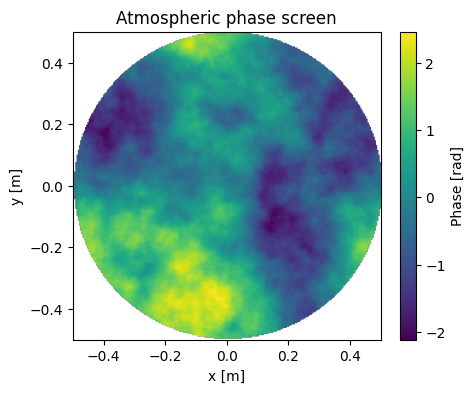

In [6]:
plt.figure(figsize=(5, 4))
plt.imshow(
    W_atm,
    extent=[
        np.nanmin(X),
        np.nanmax(X),
        np.nanmin(Y),
        np.nanmax(Y),
    ],
    origin="lower",
)
plt.colorbar(label="Phase [rad]")
plt.title("Atmospheric phase screen")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.show()

In [2]:
def run_modal_reconstruction_with_max_order(
    W_true,
    X,
    Y,
    rho,
    theta,
    mask,
    max_radial_order,
    n_lenslets=20,
    noise_std=0.0,
    seed=1,
    rcond=1e-4,
):
    """
    Reconstruct wavefront using Zernike modes up to max_radial_order.
    """
    modes = generate_zernike_modes(
        rho,
        theta,
        mask,
        max_radial_order=max_radial_order,
        include_piston=False,
        normalization=True,
    )

    centers, slopes = measure_slopes(
        W_true,
        mask,
        X,
        Y,
        n_lenslets=n_lenslets,
        min_fill=0.5,
        noise_std=noise_std,
        seed=seed,
    )

    A, names, _ = build_response_matrix(
        modes,
        mask,
        X,
        Y,
        n_lenslets=n_lenslets,
        min_fill=0.5,
    )

    coeffs, W_rec, residuals, rank, singular_values = reconstruct_wavefront(
        slopes,
        A,
        modes,
        names,
        mask,
        rcond=rcond,
    )

    res = residual_wavefront(W_true, W_rec, mask)

    if singular_values[-1] > 0:
        condition_number = singular_values[0] / singular_values[-1]
    else:
        condition_number = np.inf

    return {
        "modes": modes,
        "names": names,
        "coeffs": coeffs,
        "centers": centers,
        "slopes": slopes,
        "A": A,
        "W_rec": W_rec,
        "residual": res,
        "input_rms": rms(W_true, mask),
        "residual_rms": rms(res, mask),
        "rank": rank,
        "singular_values": singular_values,
        "condition_number": condition_number,
        "n_modes": len(names),
    }

In [7]:
lenslet_values = np.array([8, 10, 12, 14, 16, 20, 24])
max_orders = np.array([2, 3, 4, 5, 6, 7, 8, 9, 10])

noise_std = 0.0
rcond = 1e-4

residual_map = np.zeros((len(max_orders), len(lenslet_values)))
strehl_map = np.zeros_like(residual_map)
condition_map = np.zeros_like(residual_map)
rank_map = np.zeros_like(residual_map)
n_modes_map = np.zeros_like(residual_map)

for i, max_order in enumerate(max_orders):
    for j, n_lens in enumerate(lenslet_values):
        result = run_modal_reconstruction_with_max_order(
            W_atm,
            X,
            Y,
            rho,
            theta,
            mask,
            max_radial_order=int(max_order),
            n_lenslets=int(n_lens),
            noise_std=noise_std,
            seed=1,
            rcond=rcond,
        )

        residual_map[i, j] = result["residual_rms"]
        strehl_map[i, j] = strehl_ratio(
            result["residual"],
            mask,
            pad_factor=4,
        )
        condition_map[i, j] = result["condition_number"]
        rank_map[i, j] = result["rank"]
        n_modes_map[i, j] = result["n_modes"]

        print(
            f"order={max_order:2d}, "
            f"lenslets={n_lens:2d}, "
            f"modes={result['n_modes']:3d}, "
            f"rank={result['rank']:3d}, "
            f"residual={result['residual_rms']:.4f}, "
            f"Strehl={strehl_map[i, j]:.4f}, "
            f"cond={result['condition_number']:.2e}"
        )

order= 2, lenslets= 8, modes=  5, rank=  5, residual=0.8014, Strehl=0.5999, cond=1.50e+00
order= 2, lenslets=10, modes=  5, rank=  5, residual=0.7898, Strehl=0.5959, cond=1.42e+00
order= 2, lenslets=12, modes=  5, rank=  5, residual=0.7880, Strehl=0.5842, cond=1.56e+00
order= 2, lenslets=14, modes=  5, rank=  5, residual=0.7752, Strehl=0.5779, cond=1.38e+00
order= 2, lenslets=16, modes=  5, rank=  5, residual=0.7653, Strehl=0.5704, cond=1.30e+00
order= 2, lenslets=20, modes=  5, rank=  5, residual=0.7561, Strehl=0.5686, cond=1.33e+00
order= 2, lenslets=24, modes=  5, rank=  5, residual=0.7558, Strehl=0.5611, cond=1.45e+00
order= 3, lenslets= 8, modes=  9, rank=  9, residual=0.6886, Strehl=0.6698, cond=2.40e+00
order= 3, lenslets=10, modes=  9, rank=  9, residual=0.6535, Strehl=0.6626, cond=1.98e+00
order= 3, lenslets=12, modes=  9, rank=  9, residual=0.6798, Strehl=0.6867, cond=2.20e+00
order= 3, lenslets=14, modes=  9, rank=  9, residual=0.6713, Strehl=0.6941, cond=1.87e+00
order= 3, 

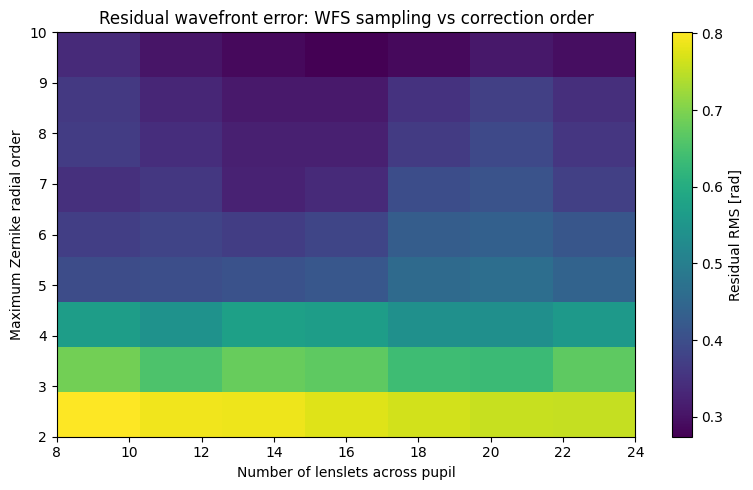

In [8]:
plt.figure(figsize=(8, 5))

im = plt.imshow(
    residual_map,
    origin="lower",
    aspect="auto",
    extent=[
        lenslet_values[0],
        lenslet_values[-1],
        max_orders[0],
        max_orders[-1],
    ],
)

plt.colorbar(im, label="Residual RMS [rad]")
plt.xlabel("Number of lenslets across pupil")
plt.ylabel("Maximum Zernike radial order")
plt.title("Residual wavefront error: WFS sampling vs correction order")

plt.tight_layout()
plt.show()

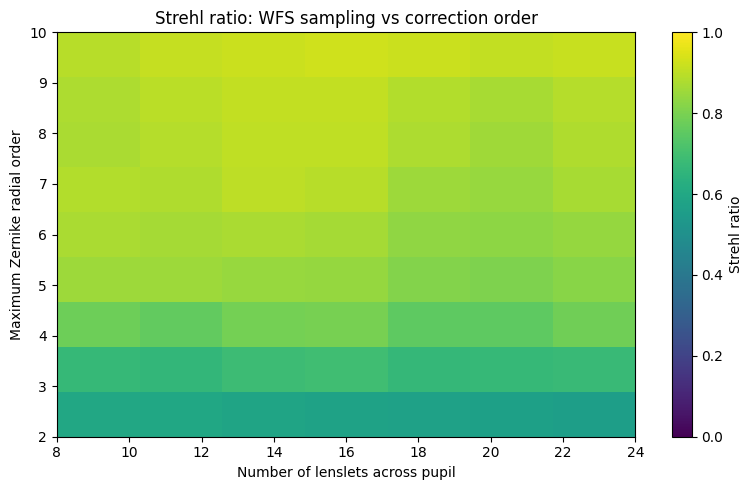

In [9]:
plt.figure(figsize=(8, 5))

im = plt.imshow(
    strehl_map,
    origin="lower",
    aspect="auto",
    extent=[
        lenslet_values[0],
        lenslet_values[-1],
        max_orders[0],
        max_orders[-1],
    ],
    vmin=0,
    vmax=1,
)

plt.colorbar(im, label="Strehl ratio")
plt.xlabel("Number of lenslets across pupil")
plt.ylabel("Maximum Zernike radial order")
plt.title("Strehl ratio: WFS sampling vs correction order")

plt.tight_layout()
plt.show()

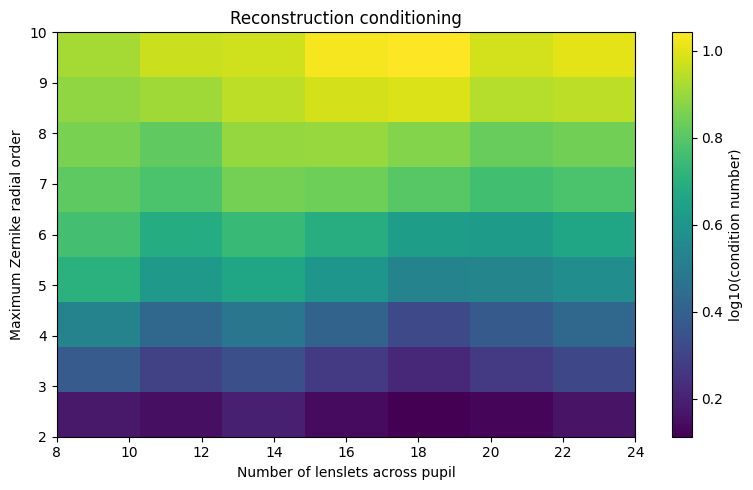

In [10]:
plt.figure(figsize=(8, 5))

im = plt.imshow(
    np.log10(condition_map),
    origin="lower",
    aspect="auto",
    extent=[
        lenslet_values[0],
        lenslet_values[-1],
        max_orders[0],
        max_orders[-1],
    ],
)

plt.colorbar(im, label="log10(condition number)")
plt.xlabel("Number of lenslets across pupil")
plt.ylabel("Maximum Zernike radial order")
plt.title("Reconstruction conditioning")

plt.tight_layout()
plt.show()

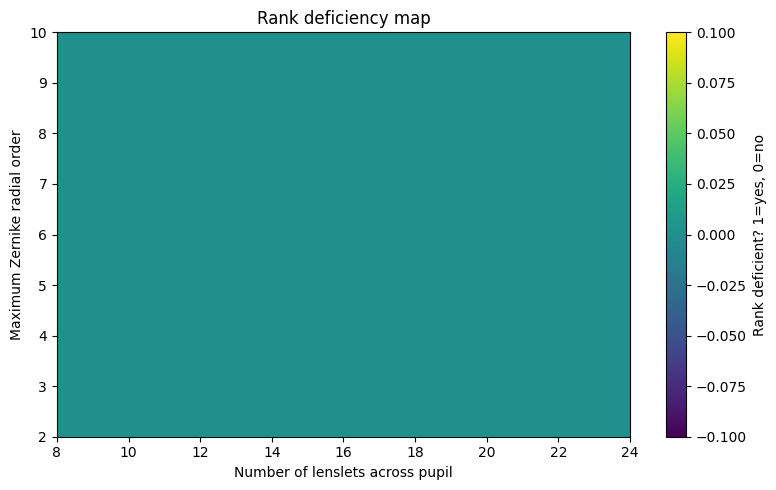

In [11]:
rank_deficient = rank_map < n_modes_map

plt.figure(figsize=(8, 5))

im = plt.imshow(
    rank_deficient,
    origin="lower",
    aspect="auto",
    extent=[
        lenslet_values[0],
        lenslet_values[-1],
        max_orders[0],
        max_orders[-1],
    ],
)

plt.colorbar(im, label="Rank deficient? 1=yes, 0=no")
plt.xlabel("Number of lenslets across pupil")
plt.ylabel("Maximum Zernike radial order")
plt.title("Rank deficiency map")

plt.tight_layout()
plt.show()

## Interpretation: WFS Sampling vs Correction Order

The heatmaps show the trade-off between Shack-Hartmann WFS sampling density and Zernike correction order for the reconstruction of an atmospheric phase screen.

The residual wavefront RMS decreases primarily with increasing maximum Zernike radial order. This indicates that the dominant limitation in this experiment is the finite correction order rather than the number of Shack-Hartmann sub-apertures. Low-order Zernike modes can only remove the large-scale components of the atmospheric phase screen, while higher-order modes can represent progressively smaller spatial structures. Therefore, increasing the reconstruction order reduces the modal fitting error.

The Strehl-ratio heatmap shows the corresponding improvement in focal-plane image quality. As the maximum Zernike order increases, the residual phase error decreases and more optical energy is concentrated back into the diffraction-limited PSF core. This leads to a higher Strehl ratio.

The dependence on the number of lenslets is weaker and not strictly monotonic. In this parameter range, even the lower lenslet numbers provide enough slope measurements to reconstruct the selected Zernike modes. Increasing the number of lenslets improves the WFS sampling, but it does not automatically improve the correction if the reconstruction basis is still limited. In other words, better WFS sampling alone is not equivalent to higher-order AO correction.

The reconstruction-conditioning map shows that the condition number increases with increasing Zernike order. This is expected because higher-order modes contain finer spatial structures and are more difficult to sense robustly with a finite lenslet array. A larger condition number means that the inverse reconstruction becomes more sensitive to measurement noise and numerical errors.

The rank-deficiency map is zero over the full scanned parameter range. This means that, for all tested combinations of lenslet number and Zernike order, the response matrix has full rank and all selected modes are formally observable by the Shack-Hartmann WFS. Therefore, the reconstruction problem is not underdetermined in this scan.
